Predicting Stock Market Prices	Engineer a comprehensive set of lagged features for the TSLA Close price across multiple time windows to capture temporal dependencies and enhance predictive power in time series forecasting models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset and sort chronologically before shifting
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print(f"Loaded {len(df)} rows ({df['Date'].min().date()} to {df['Date'].max().date()})")
df[['Date', 'Close']].head()

Loaded 100 rows (2025-01-02 to 2025-05-14)


,Date,Close
0,2025-01-02,381.88
1,2025-01-03,376.36
2,2025-01-06,380.68
3,2025-01-07,386.06
4,2025-01-08,375.53


In [3]:
# 1. Direct Price Lags, Multi-Day Differences & Percentage Momentum (Short-, Medium-, Monthly-term)
lag_windows = [1, 2, 3, 5, 7, 14, 21]

for lag in lag_windows:
    # Past closing prices
    df[f'Close_Lag_{lag}'] = df['Close'].shift(lag)
    # Past momentum strictly up to t-1 (shifted by 1 to avoid target leakage)
    df[f'Past_Diff_{lag}'] = df['Close'].shift(1) - df['Close'].shift(1 + lag)
    df[f'Past_PctChange_{lag}'] = (df['Close'].shift(1) / df['Close'].shift(1 + lag)) - 1

# 2. Lagged Rolling Window Aggregations (shifted by 1 so day t never leaks into features)
for window in [5, 10, 20]:
    shifted_close = df['Close'].shift(1)
    df[f'Lag_Roll_Mean_{window}'] = shifted_close.rolling(window=window).mean()
    df[f'Lag_Roll_Std_{window}'] = shifted_close.rolling(window=window).std()
    df[f'Lag_Roll_Min_{window}'] = shifted_close.rolling(window=window).min()
    df[f'Lag_Roll_Max_{window}'] = shifted_close.rolling(window=window).max()
    # Relative position of yesterday's close inside the trailing window [0 to 1]
    df[f'Lag_Price_Position_{window}'] = (
        (shifted_close - df[f'Lag_Roll_Min_{window}']) /
        (df[f'Lag_Roll_Max_{window}'] - df[f'Lag_Roll_Min_{window}'])
    )

# Drop initial warm-up NaN rows to prepare a clean forecasting matrix
df_features = df.dropna().reset_index(drop=True)

print(f"Total Engineered Columns : {df_features.shape[1]}")
print(f"Usable Modeling Rows     : {df_features.shape[0]} (after dropping {len(df) - len(df_features)} warm-up rows)")
df_features[['Date', 'Close', 'Close_Lag_1', 'Close_Lag_5', 'Close_Lag_14', 'Close_Lag_21', 'Lag_Roll_Mean_5']].head()

Total Engineered Columns : 42
Usable Modeling Rows     : 78 (after dropping 22 warm-up rows)


,Date,Close,Close_Lag_1,Close_Lag_5,Close_Lag_14,Close_Lag_21,Lag_Roll_Mean_5
0,2025-01-30,379.56,380.38,380.49,368.04,376.36,378.982
1,2025-01-31,376.02,379.56,375.42,368.04,380.68,378.796
2,2025-02-03,382.94,376.02,378.17,363.54,386.06,378.916
3,2025-02-04,382.29,382.94,380.45,368.58,375.53,379.870
4,2025-02-05,380.13,382.29,380.38,373.06,368.56,380.238


--- Pearson Correlation with Target (Close) ---
Close_Lag_1     0.9301
Close_Lag_2     0.8645
Close_Lag_3     0.8045
Close_Lag_5     0.7522
Close_Lag_7     0.6959
Close_Lag_14    0.6880
Close_Lag_21    0.5589


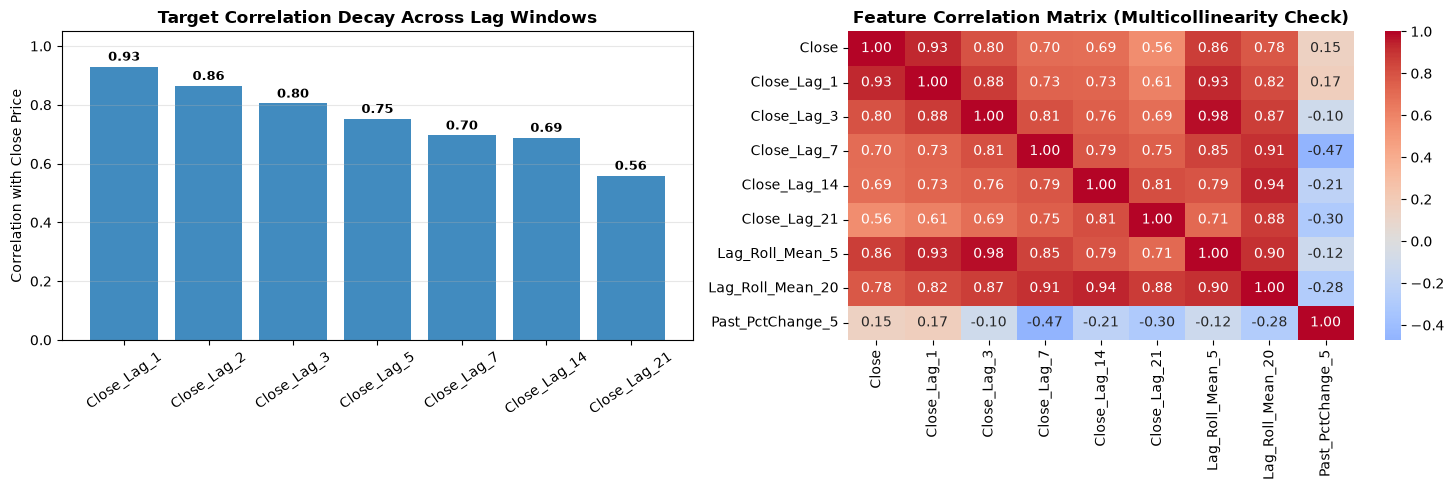

In [4]:
lag_cols = [f'Close_Lag_{lag}' for lag in lag_windows]
corr_series = df_features[['Close'] + lag_cols].corr()['Close'].drop('Close')

print("--- Pearson Correlation with Target (Close) ---")
print(corr_series.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Correlation Decay Across Lag Horizons
bars = axes[0].bar(corr_series.index, corr_series.values, color='#1f77b4', alpha=0.85)
axes[0].set_title('Target Correlation Decay Across Lag Windows', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Correlation with Close Price')
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis='x', rotation=35)
axes[0].grid(axis='y', alpha=0.3)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f"{bar.get_height():.2f}", ha='center', fontsize=9, fontweight='bold')

# Plot 2: Heatmap of Key Lagged & Rolling Features
selected_cols = ['Close', 'Close_Lag_1', 'Close_Lag_3', 'Close_Lag_7', 'Close_Lag_14', 'Close_Lag_21',
                 'Lag_Roll_Mean_5', 'Lag_Roll_Mean_20', 'Past_PctChange_5']
sns.heatmap(df_features[selected_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Feature Correlation Matrix (Multicollinearity Check)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()